In [2]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense,Flatten

In [3]:
(X_train,y_train),(X_test,y_test)=keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [7]:
X_train.shape

(60000, 28, 28)

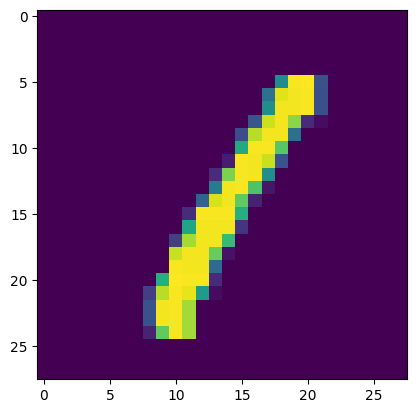

In [10]:
import matplotlib.pyplot as plt
plt.imshow(X_train[3])

# shob value ke 0/1 e convert korbo

In [14]:
X_train =X_train/255
X_test=X_test/255

In [28]:
model = Sequential()

#flatten =  higher dim array ke 1d te convert kore
model.add(Flatten(input_shape=(28,28)))
#making layers
model.add(Dense(128,activation='relu'))
model.add(Dense(32,activation='relu'))
model.add(Dense(10,activation='softmax')) # 1 er beshi node thakle softmax use korte hobe

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [29]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,938 (409.91 KB)

 Trainable params: 104,938 (409.91 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
# loss='sparse_categorical_crossentropy use korle ohe lage na and loss='categorical_crossentropy' use korle ohe lage
model.compile(loss='sparse_categorical_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [41]:
from sklearn import metrics
history = model.fit(X_train,y_train,epochs=25,validation_split=0.2)

Epoch 1/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9969 - loss: 0.0083 - val_accuracy: 0.9786 - val_loss: 0.1564
Epoch 2/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9980 - loss: 0.0060 - val_accuracy: 0.9753 - val_loss: 0.1786
Epoch 3/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9971 - loss: 0.0088 - val_accuracy: 0.9763 - val_loss: 0.1747
Epoch 4/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9978 - loss: 0.0076 - val_accuracy: 0.9781 - val_loss: 0.1681
Epoch 5/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9980 - loss: 0.0057 - val_accuracy: 0.9762 - val_loss: 0.1823
Epoch 6/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.9972 - loss: 0.0101 - val_accuracy: 0.9755 - val_loss: 0.1786
Epoch 7/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 14s 9ms/step - accuracy: 0.9984 - loss: 0.0046 - val_accuracy: 0.9778 - val_loss: 0.1777
Epoch 8/25
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 22s 10ms/step - accuracy: 0.9975 - loss: 0.0

In [42]:
y_prob = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [43]:
y_prob

array([[3.6184252e-27, 3.1705399e-19, 1.3859592e-16, ..., 9.9999994e-01,
        3.0913034e-16, 5.7040267e-12],
       [2.3349099e-29, 5.9524990e-27, 9.9999994e-01, ..., 2.2981117e-31,
        5.9415564e-22, 1.9865254e-28],
       [3.3828569e-12, 9.9999768e-01, 3.9981360e-10, ..., 4.5209345e-10,
        2.2778675e-06, 6.7713058e-16],
       ...,
       [2.3071875e-37, 2.8055195e-24, 3.0965049e-33, ..., 3.9528420e-16,
        2.9908111e-19, 1.4915537e-15],
       [2.1091700e-31, 5.5623222e-34, 1.3476993e-32, ..., 1.1305000e-24,
        8.5433271e-07, 3.0870475e-23],
       [1.7763095e-25, 7.5605064e-29, 1.6472777e-27, ..., 0.0000000e+00,
        1.3442381e-27, 1.6502887e-29]], shape=(10000, 10), dtype=float32)

In [44]:
y_pred= y_prob.argmax(axis=1)

In [45]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)*100

97.54

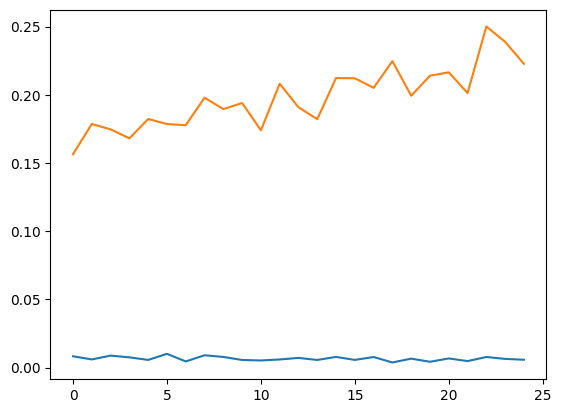

In [46]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

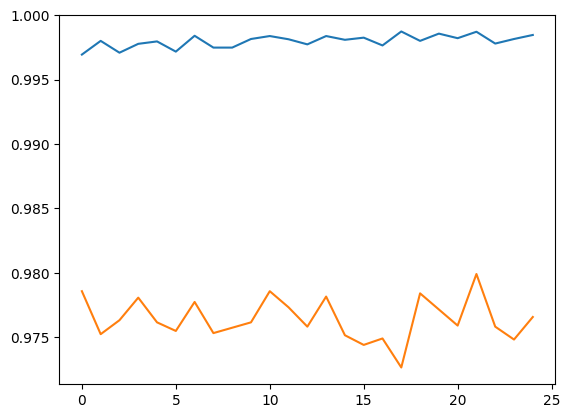

In [47]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

# here comes overfitting
# main funda was use multiclass classification using ANN

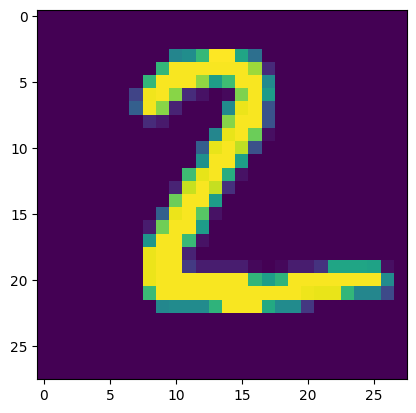

In [49]:
#check model is correct or not

plt.imshow(X_test[1])

In [50]:
model.predict(X_test[1].reshape(1,28,28)).argmax(axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


array([2])